# Setup

In [81]:
import pandas as pd

df = pd.read_csv("riftbound_all_price_history.csv")

In [82]:
# Start with the table's dimensions and a few rows so we can understand the unit of observation.
# This helps reveal whether each row represents a card, a price observation, or another entity.
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")
display(df.head())



Rows: 457,039 | Columns: 12


,date,product_id,name,set,number,printing,market_price_usd,url,snapshot_date,low,market,tickerMint_url
0,NaN,712806,Legacy - Booster Display,Legacy,NaN,Normal,NaN,https://tickermint.cards/card/712806,2026-08-29,349.99,NaN,https://tickermint.cards/card/712806
1,NaN,712806,Legacy - Booster Display,Legacy,NaN,Normal,NaN,https://tickermint.cards/card/712806,2026-08-30,349.99,NaN,https://tickermint.cards/card/712806
2,NaN,712806,Legacy - Booster Display,Legacy,NaN,Normal,NaN,https://tickermint.cards/card/712806,2026-08-31,349.92,NaN,https://tickermint.cards/card/712806
3,NaN,712806,Legacy - Booster Display,Legacy,NaN,Normal,NaN,https://tickermint.cards/card/712806,2026-09-01,349.92,NaN,https://tickermint.cards/card/712806
4,NaN,712806,Legacy - Booster Display,Legacy,NaN,Normal,NaN,https://tickermint.cards/card/712806,2026-09-02,349.99,NaN,https://tickermint.cards/card/712806


In [83]:
# Inspect column types and non-null counts before choosing cleaning or analysis steps.
# Types can expose values that were loaded as text even though they should be numeric or dates.
df.info()

# Summarize missingness; percentages make it easier to prioritize columns with substantial gaps.
missing = df.isna().sum().to_frame("missing_count")
missing["missing_percent"] = (missing["missing_count"] / len(df) * 100).round(2)
display(missing.loc[missing["missing_count"] > 0].sort_values("missing_percent", ascending=False))

# Exact duplicate rows may indicate repeated observations or an upstream data issue.
print(f"Exact duplicate rows: {df.duplicated().sum():,}")



<class 'pandas.DataFrame'>
RangeIndex: 457039 entries, 0 to 457038
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   date              450922 non-null  str    
 1   product_id        457039 non-null  int64  
 2   name              457039 non-null  str    
 3   set               457039 non-null  str    
 4   number            443336 non-null  str    
 5   printing          457039 non-null  str    
 6   market_price_usd  450922 non-null  float64
 7   url               457039 non-null  str    
 8   snapshot_date     457039 non-null  str    
 9   low               457039 non-null  float64
 10  market            438907 non-null  float64
 11  tickerMint_url    457039 non-null  str    
dtypes: float64(3), int64(1), str(8)
memory usage: 41.8 MB


,missing_count,missing_percent
market,18132,3.97
number,13703,3.00
date,6117,1.34
market_price_usd,6117,1.34


Exact duplicate rows: 0


In [84]:
# Check what the difference is between data and snapshot_date
df[['product_id','name','date', 'snapshot_date']]

,product_id,name,date,snapshot_date
0,712806,Legacy - Booster Display,NaN,2026-08-29
1,712806,Legacy - Booster Display,NaN,2026-08-30
2,712806,Legacy - Booster Display,NaN,2026-08-31
3,712806,Legacy - Booster Display,NaN,2026-09-01
4,712806,Legacy - Booster Display,NaN,2026-09-02
...,...,...,...,...
457034,672088,Aspirant's Climb,2026-10-11,2026-10-07
457035,672088,Aspirant's Climb,2026-10-11,2026-10-08
457036,672088,Aspirant's Climb,2026-10-11,2026-10-09
457037,672088,Aspirant's Climb,2026-10-11,2026-10-10


In [85]:
#Looks like date is the day the dataset was downloaded
#From this I know we can drop date and the url columns as they will not be releveant to the market analysis
df['date'].unique()

<StringArray>
[nan, '2026-10-11']
Length: 2, dtype: str

In [102]:
print(df['market_price_usd'].equals(df['market']))


False


In [103]:
# Number of distinct prices each product_id has taken
n_prices = singles.groupby('product_id')['market_price_usd'].nunique()

print(n_prices.value_counts().sort_index())          # how many cards have 1, 2, 3... distinct prices
print("Cards with a constant price:", (n_prices == 1).sum(), "of", len(n_prices))
print("Share constant:", (n_prices == 1).mean())

market_price_usd
1    1439
Name: count, dtype: int64
Cards with a constant price: 1439 of 1439
Share constant: 1.0


In [104]:
# Number of distinct prices each product_id has taken
n_prices = singles.groupby('product_id')['market'].nunique()

print(n_prices.value_counts().sort_index())          # how many cards have 1, 2, 3... distinct prices
print("Cards with a constant price:", (n_prices == 1).sum(), "of", len(n_prices))
print("Share constant:", (n_prices == 1).mean())

market
1       9
2      10
3       5
4       4
5       4
       ..
392     1
406     1
439     1
442     1
452     1
Name: count, Length: 284, dtype: int64
Cards with a constant price: 9 of 1439
Share constant: 0.006254343293954135


In [86]:
# Drop unnecessary columns and rows with missing market prices
# Change the data types of certain columns so they are more accurate
# Dropping NaN values is appropriate here since the focus is on pricing movement.
df_cleaned = df[df['market_price_usd'].notna()].drop(columns=['date', 'url', 'tickerMint_url']).dropna()

df_cleaned['market_price_usd'] = df_cleaned['market_price_usd'].astype(float)
df_cleaned['product_id'] = df_cleaned['product_id'].astype(int)
df_cleaned['snapshot_date'] = pd.to_datetime(df_cleaned['snapshot_date'])
df_cleaned.head()

,product_id,name,set,number,printing,market_price_usd,snapshot_date,low,market
758,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.0,2026-09-28,1100.00,617.5
759,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.0,2026-09-29,1098.71,617.5
760,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.0,2026-09-30,1098.71,617.5
761,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.0,2026-10-01,999.99,617.5
762,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.0,2026-10-02,999.99,617.5


# Since the dataset combines both sealed and singles I believe it is important to seperate the 2 in distinct datasets

In [87]:
singles = df_cleaned[df_cleaned['number'].notna()]
singles.head()

,product_id,name,set,number,printing,market_price_usd,snapshot_date,low,market
758,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.0,2026-09-28,1100.00,617.5
759,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.0,2026-09-29,1098.71,617.5
760,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.0,2026-09-30,1098.71,617.5
761,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.0,2026-10-01,999.99,617.5
762,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.0,2026-10-02,999.99,617.5


In [88]:
sealed = df_cleaned[df_cleaned['number'].isna()]
sealed.head()

,product_id,name,set,number,printing,market_price_usd,snapshot_date,low,market


# Singles Data Cleaning & Exploration
### Start with this to try to spot any trends

In [89]:
singles 

,product_id,name,set,number,printing,market_price_usd,snapshot_date,low,market
758,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.00,2026-09-28,1100.00,617.50
759,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.00,2026-09-29,1098.71,617.50
760,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.00,2026-09-30,1098.71,617.50
761,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.00,2026-10-01,999.99,617.50
762,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.00,2026-10-02,999.99,617.50
...,...,...,...,...,...,...,...,...,...
457034,672088,Aspirant's Climb,Riftbound Worlds Bundle 2025,276a/298,Foil,41.83,2026-10-07,30.00,43.57
457035,672088,Aspirant's Climb,Riftbound Worlds Bundle 2025,276a/298,Foil,41.83,2026-10-08,30.00,42.77
457036,672088,Aspirant's Climb,Riftbound Worlds Bundle 2025,276a/298,Foil,41.83,2026-10-09,30.00,41.83
457037,672088,Aspirant's Climb,Riftbound Worlds Bundle 2025,276a/298,Foil,41.83,2026-10-10,30.00,41.83


In [90]:
singles.groupby('product_id')['market_price_usd'].mean()

product_id
652771       0.20
652772       0.16
652773       0.14
652774       0.33
652775       0.21
           ...   
716021    1498.00
716026    1300.00
716035    1233.33
721767       0.10
721871     300.00
Name: market_price_usd, Length: 1439, dtype: float64

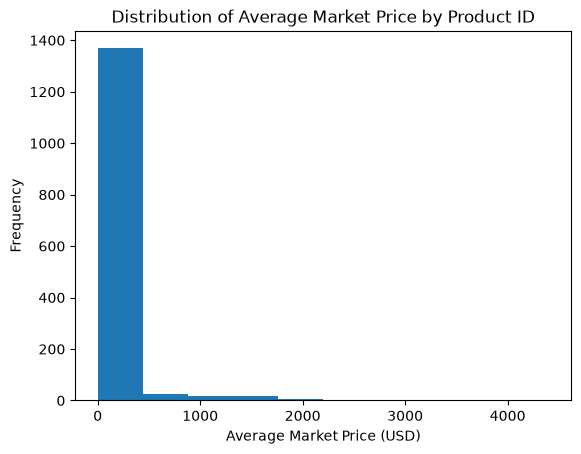

In [91]:
import matplotlib.pyplot as plt

singles.groupby('product_id')['market_price_usd'].mean().plot(kind='hist', bins = 10)
plt.xlabel('Average Market Price (USD)')
plt.ylabel('Frequency')
plt.title('Distribution of Average Market Price by Product ID')
plt.show()

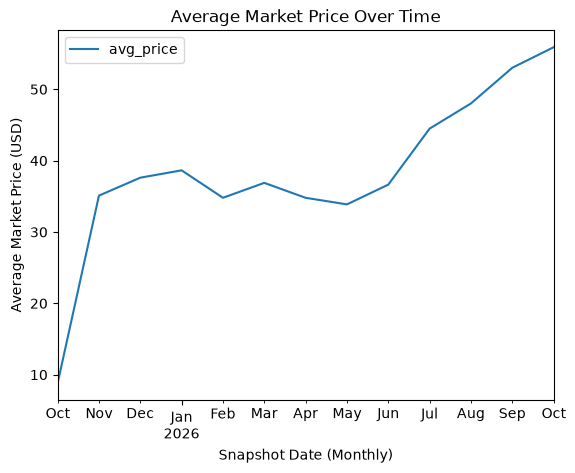

In [92]:
monthly = singles.groupby(
    singles['snapshot_date'].dt.to_period('M')
).agg(
    avg_price=('market_price_usd', 'mean'),
    card_count=('market_price_usd', 'count')
)

monthly.plot(y='avg_price', kind='line')
plt.xlabel('Snapshot Date (Monthly)')
plt.ylabel('Average Market Price (USD)')
plt.title('Average Market Price Over Time')
plt.show()

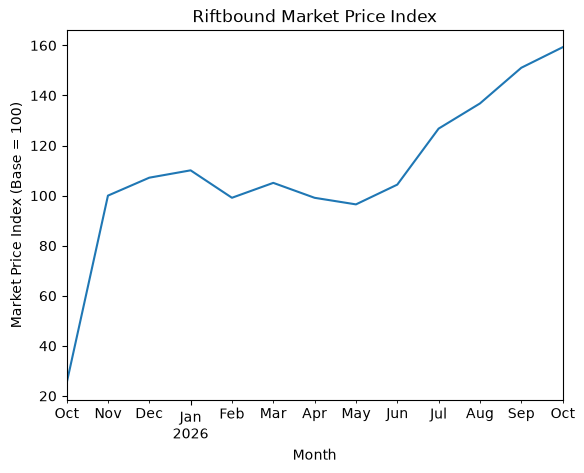

In [93]:
monthly['price_index'] = (
    monthly['avg_price'] / monthly['avg_price'].iloc[1]
) * 100

monthly['price_index'].plot(kind='line')

plt.xlabel('Month')
plt.ylabel('Market Price Index (Base = 100)')
plt.title('Riftbound Market Price Index')
plt.show()

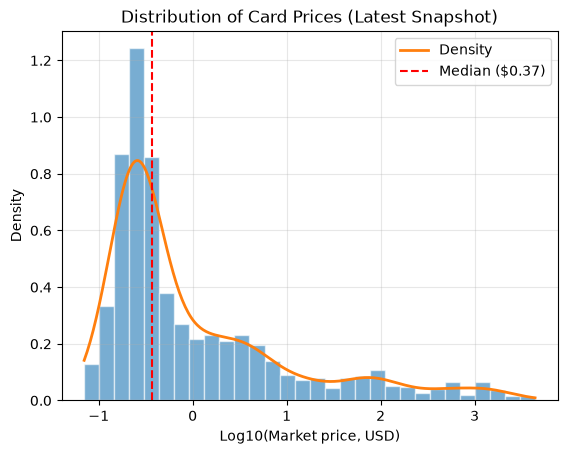

In [94]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

latest = singles[singles['snapshot_date'] == singles['snapshot_date'].max()]
prices = latest['market_price_usd']
log_data = np.log10(prices[prices > 0].dropna())   # log10(0) = -inf breaks the plot

# Histogram as density so the line is on the same scale
plt.hist(log_data, bins=30, density=True, alpha=0.6, edgecolor="white")

# Smooth density line (KDE)
x = np.linspace(log_data.min(), log_data.max(), 300)
plt.plot(x, gaussian_kde(log_data)(x), linewidth=2, label="Density")

# Optional: vertical median line
plt.axvline(log_data.median(), color="red", linestyle="--", label=f"Median (${10**log_data.median():.2f})")

plt.xlabel("Log10(Market price, USD)")
plt.ylabel("Density")
plt.title("Distribution of Card Prices (Latest Snapshot)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [95]:
latest = singles[singles['snapshot_date'] == singles['snapshot_date'].max()]
p = latest['market_price_usd'].dropna()
p = p[p > 0]

print(p.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]))
print("Mean / median:", p.mean() / p.median())

# Share of total market value held by the top cards
s = p.sort_values(ascending=False)
for k in [10, 25, 50]:
    print(f"Top {k} cards = {s.head(k).sum() / s.sum():.1%} of total value")

count    1948.000000
mean       58.429923
std       295.384709
min         0.070000
10%         0.160000
25%         0.230000
50%         0.370000
75%         2.480000
90%        45.742000
95%       175.297500
99%      1499.049400
max      4400.000000
Name: market_price_usd, dtype: float64
Mean / median: 157.9187108052611
Top 10 cards = 26.7% of total value
Top 25 cards = 47.7% of total value
Top 50 cards = 71.8% of total value


In [96]:
bins   = [0, 0.25, 1, 5, 25, np.inf]
labels = ["bulk (<$0.25)", "$0.25-1", "$1-5", "$5-25", "$25+"]
latest = latest.assign(tier=pd.cut(latest['market_price_usd'], bins=bins, labels=labels))
print(latest['tier'].value_counts().sort_index())

tier
bulk (<$0.25)    627
$0.25-1          660
$1-5             306
$5-25            134
$25+             221
Name: count, dtype: int64


In [97]:
piv = singles.pivot_table(index='snapshot_date', columns='product_id',
                          values='price_usd')
basket = piv.dropna(axis=1)                     # cards present on all dates
rel = basket / basket.iloc[0]                   # each card relative to day 1
index_equal = rel.median(axis=1) * 100          # robust "typical card" index
index_mean  = rel.mean(axis=1) * 100            # equal-weighted, mean

print(index_equal.tail())
print(index_mean.tail())


KeyError: 'price_usd'